# MAGIC Telescope & Concrete Strength: Mock Exam Solutions (Data & AI 3)

Answer key for the **Data & AI 3** (T1) mock exam. My own answers are in `mock-exam-my-answers.ipynb`. This key has no solution for Q10.

**Datasets:**
- `data/magic04.csv`: MAGIC gamma telescope measurements; `class` is `g` (gamma) or `h` (hadron)
- `data/magic04-2.csv`: a description for each class
- `../../05a-ml-basics/data/Concrete_Data.csv`: concrete ingredients and compressive strength (`csMPa`)

**Questions:**
- **Q1–Q7:** pandas, merging, min-max scaling and a boxplot
- **Q8:** a decision tree classifier for `class`, tuned with grid search
- **Q9:** the output of a tiny neural network, worked out by hand
- **Q10:** a neural network that predicts concrete strength

---

# SETUP

### Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

# sklearn utilities used in questions below
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, mean_squared_error, r2_score, f1_score
from sklearn.neural_network import MLPRegressor

### Auxiliary code

In [2]:
# small helper: sigmoid for Q9
def sigmoid(x):
    return 1 / (1 + math.exp(-x))

### Load data

In [3]:
df = pd.read_csv('data/magic04.csv')
df2 = pd.read_csv('data/magic04-2.csv')
concrete = pd.read_csv('../../05a-ml-basics/data/Concrete_Data.csv')

# quick sanity print
print('Loaded df rows,columns:', df.shape)
print('Loaded df2 rows,columns:', df2.shape)
print('Loaded concrete rows,columns:', concrete.shape)

Loaded df rows,columns: (19020, 11)
Loaded df2 rows,columns: (2, 2)
Loaded concrete rows,columns: (1030, 9)


---

# QUESTIONS

Questions 1 to 8 make use of the dataset <strong>data/magic04.csv</strong>. In addition, question 4 makes use of <strong>data/magic04-2.csv</strong>

### Question 1 (1 point)

Create a new field <em>fWidth_Double</em> with as value the value of <em>fWidth</em> multiplied by 2.

Create a new field <em>fWidth_Squared</em> with as value the value of <em>fWidth</em> squared.

<strong>Use 2 different ways to do the calculations for both subquestions: once with Pandas and once with NumPy!</strong>  

In [4]:
# Solution Q1
# Pandas way
# create a copy to avoid accidental modification if re-running cells
df_q1 = df.copy()
# using pandas vectorized operators
df_q1['fWidth_Double_pandas'] = df_q1['fWidth'] * 2
df_q1['fWidth_Squared_pandas'] = df_q1['fWidth'] ** 2

# NumPy way (demonstrates using numpy functions)
# note: pandas column supports numpy ufuncs directly
df_q1['fWidth_Double_numpy'] = np.multiply(df_q1['fWidth'], 2)
df_q1['fWidth_Squared_numpy'] = np.power(df_q1['fWidth'], 2)

# Final answer: show first rows
print('\n# Answer question 1 : first 5 rows with new columns')
print(df_q1[['fWidth','fWidth_Double_pandas','fWidth_Double_numpy','fWidth_Squared_pandas','fWidth_Squared_numpy']].head())



# Answer question 1 : first 5 rows with new columns
     fWidth  fWidth_Double_pandas  fWidth_Double_numpy  fWidth_Squared_pandas  \
0   16.0021               32.0042              32.0042             256.067204   
1   11.7235               23.4470              23.4470             137.440452   
2  136.0310              272.0620             272.0620           18504.432961   
3    9.5728               19.1456              19.1456              91.638500   
4   30.9205               61.8410              61.8410             956.077320   

   fWidth_Squared_numpy  
0            256.067204  
1            137.440452  
2          18504.432961  
3             91.638500  
4            956.077320  


### Question 2 (1 point)

Create a dataframe 'filtered_df' with the rows of df where <em>fConc</em> is greater than 0.4. Print out how many rows dataframe 'filtered_df' has.

In [5]:
# Solution Q2
filtered_df = df[df['fConc'] > 0.4]
print('\n# Answer question 2 : number of rows in filtered_df =', len(filtered_df))



# Answer question 2 : number of rows in filtered_df = 7872


### Question 3 (2 points)

For each unique value in the column `class`, calculate the median, and standard deviation of fSize

In [6]:
# Solution Q3
q3 = df.groupby('class')['fSize'].agg(['median','std'])
print('\n# Answer question 3 : median and std of fSize per class')
print(q3)



# Answer question 3 : median and std of fSize per class
        median       std
class                   
g      2.70480  0.463083
h      2.79765  0.480612


### Question 4 (1 point)

Merge the two datasets so that a description is added to every row. Inspect both to determine which columns to merge on. Save the merged DataFrame to a new variable.

In [7]:
# Solution Q4
print('\nInspecting columns of both dataframes to choose merge keys:')
print('df first rows:', df.head())
print('df2 first rows:', df2.head())

# Common column is 'class' in df and 'type' in df2
merged = pd.merge(df, df2, left_on='class', right_on='type')

print('\n# Answer question 4 : merged shape', merged.shape)
print(merged.head())



Inspecting columns of both dataframes to choose merge keys:
df first rows:     fLength    fWidth   fSize   fConc  fConc1     fAsym  fM3Long  fM3Trans  \
0   28.7967   16.0021  2.6449  0.3918  0.1982   27.7004  22.0110   -8.2027   
1   31.6036   11.7235  2.5185  0.5303  0.3773   26.2722  23.8238   -9.9574   
2  162.0520  136.0310  4.0612  0.0374  0.0187  116.7410 -64.8580  -45.2160   
3   23.8172    9.5728  2.3385  0.6147  0.3922   27.2107  -6.4633   -7.1513   
4   75.1362   30.9205  3.1611  0.3168  0.1832   -5.5277  28.5525   21.8393   

    fAlpha     fDist class  
0  40.0920   81.8828     g  
1   6.3609  205.2610     g  
2  76.9600  256.7880     g  
3  10.4490  116.7370     g  
4   4.6480  356.4620     g  
df2 first rows:   type        description
0    g  the g type - 1234
1    h  the h type - 2345

# Answer question 4 : merged shape (19020, 13)
    fLength    fWidth   fSize   fConc  fConc1     fAsym  fM3Long  fM3Trans  \
0   28.7967   16.0021  2.6449  0.3918  0.1982   27.7004  22.0

### Question 5 (2 points)

Normalize the <em>fLength</em> and <em>fWidth</em> columns to a range between 0 and 1 using min-max scaling. Print out the original <em/>fLength</em> and <em>fWidth</em> columns along with the normalized columns.

In [8]:
# Solution Q5
df_q5 = df.copy()
for col in ['fLength','fWidth']:
    minv = df_q5[col].min()
    maxv = df_q5[col].max()
    df_q5[f'{col}_minmax'] = (df_q5[col] - minv) / (maxv - minv)

#Or column per column
#df['fLength_norm'] = (df['fLength'] - df['fLength'].min()) / (df['fLength'].max() - df['fLength'].min())
#df['fWidth_norm'] = (df['fWidth'] - df['fWidth'].min()) / (df['fWidth'].max() - df['fWidth'].min())

print('\n# Answer question 5 : showing original and normalized columns (first 5 rows)')
print(df_q5[['fLength','fLength_minmax','fWidth','fWidth_minmax']].head())



# Answer question 5 : showing original and normalized columns (first 5 rows)
    fLength  fLength_minmax    fWidth  fWidth_minmax
0   28.7967        0.074306   16.0021       0.062415
1   31.6036        0.082815   11.7235       0.045727
2  162.0520        0.478241  136.0310       0.530579
3   23.8172        0.059212    9.5728       0.037338
4   75.1362        0.214774   30.9205       0.120603


### Question 6 (1 points)

Using your merged dataset from question 4, make sure the description is updated by only keeping the part before the hyphen (-)

In [9]:
# Solution Q6
merged['description'] = merged['description'].str.split('-').str.get(0)
merged.head()


,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class,type,description
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g,g,the g type
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g,g,the g type
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g,g,the g type
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g,g,the g type
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g,g,the g type


### Question 7 (2 points)

How does the distribution of <em>fWidth</em> vary across different levels of <em>fConc</em>? Plot a boxplot to compare <em>fWidth</em> distribution across several ranges or bins of <em>fConc</em>

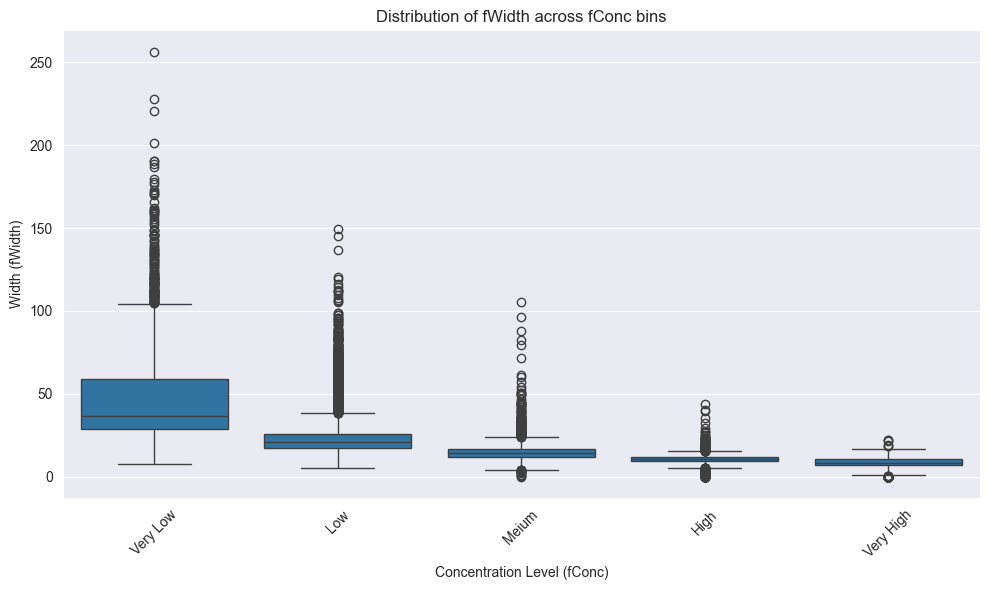

In [10]:
# Solution Q7
# Create bins for fConc and then boxplot fWidth per bin
df_q7 = df.copy()
# create 5 bins (adjust bins as needed)
df_q7['fConc_bin'] = pd.cut(df_q7['fConc'], bins=5, labels=['Very Low', 'Low', 'Meium', 'High', 'Very High'])
plt.figure(figsize=(10,6))
sns.boxplot(x='fConc_bin', y='fWidth', data=df_q7)
plt.xticks(rotation=45)
plt.title('Distribution of fWidth across fConc bins')
plt.xlabel('Concentration Level (fConc)')
plt.ylabel('Width (fWidth)')
plt.tight_layout()
plt.show()


### Question 8 (5 points)

Develop a model to predict <em>class</em> using the features <em>fLength, fWidth, fSize</em>. Use a decision tree and split your data into train and test sets (80/20 split). Use random state 42.

Use grid search with cross-validation (with 2 folds) to find the best hyperparameters. Check for following hyperparameters: 

- criterion: 'gini', 'entropy'
- max_depth': 3, 5, 10
- min_samples_split: 2, 5, 10
- min_samples_leaf: 1, 2, 4

Evaluate the quality of the best model on the test set (refit if necessary on the proper data) (is this a good model or bad model, would you use this model, explain why).

Check if this model is overfitting or underfitting and explain your answer.

List the hyperparameters you would use and explain why.

Describe what you could do to improve the model and explain why this could improve the model.

In [19]:
# Solution Q8

# DATA PREPARATION

features = ['fLength','fWidth','fSize']
X = df[features]
y = df['class']

print(X.head(5))
print(y.head(5))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    fLength    fWidth   fSize
0   28.7967   16.0021  2.6449
1   31.6036   11.7235  2.5185
2  162.0520  136.0310  4.0612
3   23.8172    9.5728  2.3385
4   75.1362   30.9205  3.1611
0    g
1    g
2    g
3    g
4    g
Name: class, dtype: object


In [20]:
# GRID SEARCH

param_grid = {
    'criterion': ['gini','entropy'],
    'max_depth': [3,5,10],
    'min_samples_split': [2,5,10],
    'min_samples_leaf': [1,2,4]
}

dt = DecisionTreeClassifier(random_state=42)
gs = GridSearchCV(dt, param_grid, cv=2)

gs.fit(X_train, y_train)

best = gs.best_estimator_ # The best estimator has already been retrained/refit on the complete dataset by default
print('\n# Answer question 8 : Best hyperparameters:', gs.best_params_)
print('This combination of hyperparameters provide the highest accuracy based on our 2-fold CV')
print('Mean cross validated score for best estimator:', gs.best_score_) # The default score metric for a decision tree in Scikit-Learn is accuracy


# Answer question 8 : Best hyperparameters: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5}
This combination of hyperparameters provide the highest accuracy based on our 2-fold CV
Mean cross validated score for best estimator: 0.7888406940063091



Classification report on test set:
              precision    recall  f1-score   support

           g       0.78      0.93      0.85      2460
           h       0.81      0.53      0.64      1344

    accuracy                           0.79      3804
   macro avg       0.80      0.73      0.75      3804
weighted avg       0.79      0.79      0.78      3804



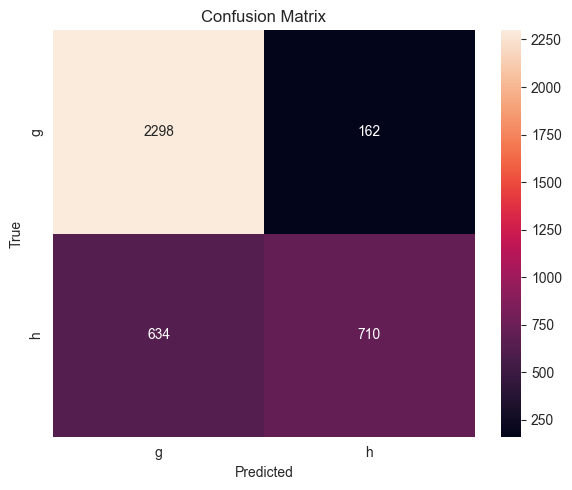


Classification report on train set:
              precision    recall  f1-score   support

           g       0.81      0.95      0.87      9872
           h       0.86      0.58      0.70      5344

    accuracy                           0.82     15216
   macro avg       0.83      0.77      0.78     15216
weighted avg       0.83      0.82      0.81     15216


Classification report on test set:
              precision    recall  f1-score   support

           g       0.78      0.93      0.85      2460
           h       0.81      0.53      0.64      1344

    accuracy                           0.79      3804
   macro avg       0.80      0.73      0.75      3804
weighted avg       0.79      0.79      0.78      3804



In [21]:
# EVALUATION

# Evaluate on test set
y_pred = best.predict(X_test)
print('\nClassification report on test set:')
print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
labels = np.unique(np.concatenate([y_test, y_pred])) # All labels for clearer interpretation
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='', xticklabels=labels, yticklabels=labels) # fmt='' shows the values in full
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

# Quick check for over/underfitting: compare train and test scores
y_train_pred = best.predict(X_train)
y_test_pred = best.predict(X_test)
#print('Train accuracy:', best.score(X_train, y_train))
#print('Test accuracy:', best.score(X_test, y_test))
#print('Train F1 (weighted):', f1_score(y_train, y_train_pred, average='weighted'))
#print('Test F1 (weighted):', f1_score(y_test, y_test_pred, average='weighted'))
print('\nClassification report on train set:')
print(classification_report(y_train, y_train_pred))
print('\nClassification report on test set:')
print(classification_report(y_test, y_test_pred))


# Answer question 8 : Best hyperparameters: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5}
This combination of hyperparameters provide the highest accuracy based on our 2-fold CV

Classification report on test set:
              precision    recall  f1-score   support

           g       0.78      0.93      0.85      2460
           h       0.81      0.53      0.64      1344

    accuracy                           0.79      3804
   macro avg       0.80      0.73      0.75      3804
weighted avg       0.79      0.79      0.78      3804



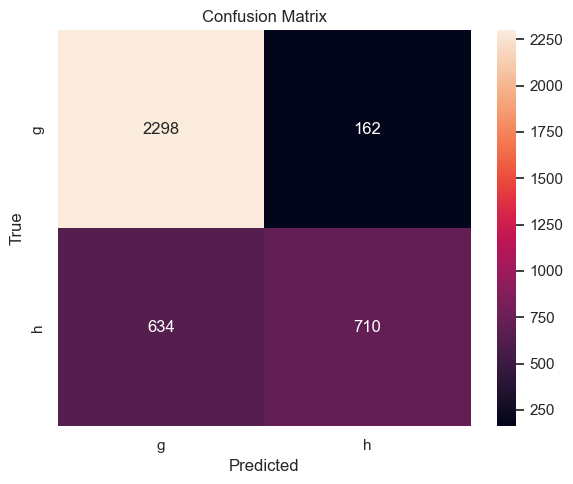

Train accuracy: 0.8202549947423764
Test accuracy: 0.7907465825446898
Train F1 (weighted): 0.8102280236212177
Test F1 (weighted): 0.7776201891257573

Interpretation:
- Training performance is slightly higher than test performance, indicating mild overfitting
- We see a clear difference between performance on the h and g class. 93% all g-class data samples are correctly predicted to be g while for the h class this only 53%
- Precision is moderate for both so if false positives are the most important, this could be a decent model for class h and possibly also for class g
- Recall is high for g but low for h, so if false negatives are important, this model wouldn't be useful

Possible improvements:
- Expand the hyperparameter search space (larger range, more hyperparameters)
- Use ensemble methods (such as RandomForest) to reduce variance.
- Use more folds in K-fold CV for more robust results


In [133]:
# CONCLUSION

print('\nInterpretation:')
print('- Training performance is slightly higher than test performance, indicating mild overfitting.')
print('- The data is a bit unbalanced, there are twice as much cases of the g-class than of the h-class.')
print('- We see a clear difference between performance on the h and g class. 93% all g-class data samples are correctly predicted to be g while for the h class this only 53%')
print('- Precision is moderate for both so if false positives are the most important, this could be a decent model for class h and possibly also for class g')
print('- Recall is high for g but low for h, so if false negatives are important, this model wouldn\'t be useful unless we only care about the g-class.')

print('\nPossible improvements:')
print('- Add more data (variables and cases).')
print('- Expand the hyperparameter search space (larger range, more hyperparameters)')
print('- Use ensemble methods (such as RandomForest) to reduce variance.')
print('- Use more folds in K-fold CV for more robust results')

### Question 9 (1 point)

A very small neural network has an input layer with 2 nodes and an output layer with 1 node. There are no hidden nodes. Calculate the feedforward pass if the input is [1, 0.5, 1] the weights are [0.3, 0.5, -0.1] and the bias is -0.7. The activation function used by the output layer is sigmoid. Do not use Tensorflow/Keras, but calculate the result yourself using Numpy arrays and the Python Math module.

In [134]:
# Solution Q9
x = np.array([1, 0.5, 1])
w = np.array([0.3, 0.5, -0.1])
b = -0.7
prod = x * w                # elementwise multiplication -> array
dot = np.sum(prod)         # sum of products -> scalar
linear = float(dot + b)    # add bias and cast to float

# Or in one line: linear = float(np.dot(x, w) + b)
activation = sigmoid(linear)
print('\n# Answer question 9 :')
print('Linear output (weighted sum + bias):', linear)
print('Sigmoid activation output:', activation)



# Answer question 9 :
Linear output (weighted sum + bias): -0.2499999999999999
Sigmoid activation output: 0.43782349911420193


### Question 10 (5 points)

This question makes use of dataset <strong>../../05a-ml-basics/data/Concrete_Data.csv</strong>

Develop a model to predict <em>csMPa</em> based on a neural network using <em>cement</em>, <em>slag</em>, <em>coarseaggregate</em>, <em>age</em> and <em>fineaggregate</em> as predictors.

Do some parameter tuning (for at least two parameters).

Evaluate the quality of the model (is this a good model or bad model, would you use this model, explain why).

Describe what you could do to improve the model and explain why this could improve the model.

# END OF EXAM

---